First version of a script to process incredibly grainy image data. Shelved because the Randomized Hough Transform used to fit curved lines turned out to not be a good algorithm for the data.

In [ ]:
import skimage as ski
import os 
import numpy as np
from PIL import Image
from scipy.fft import fft2, fftshift
from scipy.ndimage import median_filter

from skimage.restoration import (
    denoise_tv_chambolle,
    denoise_bilateral,
    denoise_wavelet,
    estimate_sigma,
)

import matplotlib.pyplot as plt

import numpy as np

from skimage.transform import hough_line, hough_line_peaks
from skimage.feature import canny
from skimage.draw import line as draw_line
from skimage import data

import matplotlib.pyplot as plt
from matplotlib import cm


In [3]:
# plan
# -> Crop more closely
# -> Fit a 5 degree polynomial for horizontal. 


In [4]:
# Utility

def to_u8(img):
    return ((img - img.min()) / (img.max() - img.min()) * 255).astype(np.uint8)

def get_file(num, prefix = 'imgs2/raw', suffix = ".tif"):

    filename = os.path.join('.', prefix, f'{num:0>5}{suffix}')
    img=ski.io.imread(filename)
    return img

def get_avg_img(num, k=2):
    img_sum = get_file(num-k).astype(np.uint16)
    #disp(img_sum)
    for i in range(num-k+1, num+k+1):
        img_sum += get_file(i).astype(np.uint16)
        #disp(to_u8(img_sum))

    return to_u8(img_sum)

def disp(img):
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_float(img):
    img = to_u8(img)
    display( Image.fromarray(np.uint8(img)).convert('RGB'))

def disp_bool(img):
    display( Image.fromarray(np.bool(img)).convert('RGB'))

def bi_dn(img):
    return denoise_bilateral(img, win_size = 5, sigma_spatial=1)

In [5]:
# Initialization
img1 = get_avg_img(6)
imgs = [get_avg_img(i, 3).astype(np.uint16) for i in range(30,600, 30)]

In [6]:
#disp(imgs[0][395:520, 270:550])

"""Return left_v, right_v, top_h, bot_h
In the interest of my sanity, we maintain a uniform left corner
"""

left_x = 200
left_y = 390
right_offset = 280
bot_offset = 1

def crop(img):
    return [img[left_y:520, left_x:320], img[left_y:520, (left_x + right_offset):540], img[left_y:left_y+50, 210:550], img[395:520, 230:550]]

570


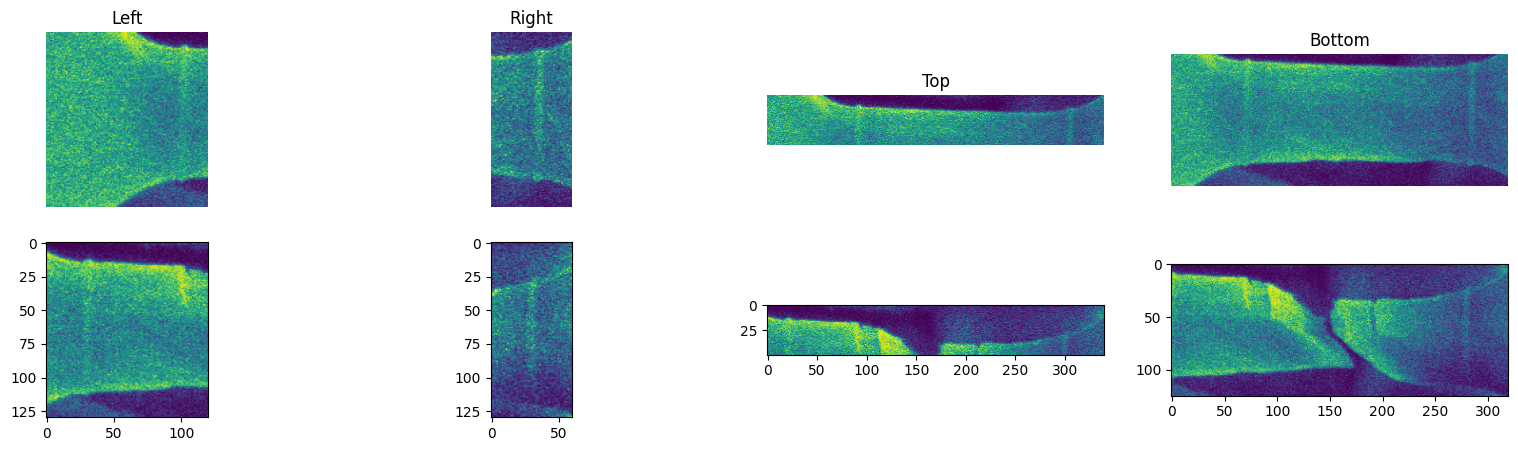

In [7]:
fig, ax = plt.subplots(2, 4, figsize=(20, 5))

img1_crops = crop(imgs[0])
img420_crops = crop(imgs[len(imgs)-1])

print(30 * len(imgs))

ax[0][0].imshow(img1_crops[0])
ax[0][0].set_axis_off()
ax[0][0].set_title('Left')
ax[0][1].imshow(img1_crops[1])
ax[0][1].set_axis_off()
ax[0][1].set_title('Right')
ax[0][2].imshow(img1_crops[2])
ax[0][2].set_axis_off()
ax[0][2].set_title('Top')
ax[0][3].imshow(img1_crops[3])
ax[0][3].set_axis_off()
ax[0][3].set_title('Bottom')

ax[1][0].imshow(img420_crops[0])
ax[1][1].imshow(img420_crops[1])
ax[1][2].imshow(img420_crops[2])
ax[1][3].imshow(img420_crops[3])

In [8]:
def add_figures(can_img, img, ax, name='Original image'):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(can_img, theta=tested_angles)

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))

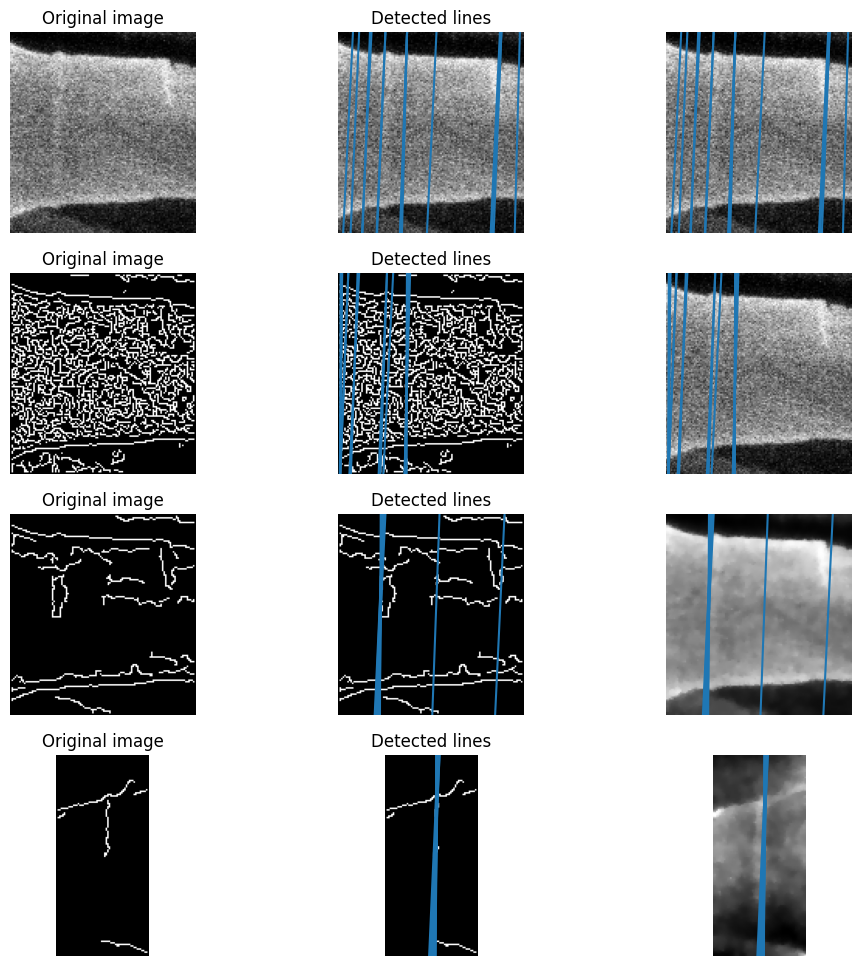

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(12, 12))

img_left=(crop(get_avg_img(570, 3)))[0]
img_right=(crop(get_avg_img(570, 3)))[1]

def add_figures(can_img, img, ax, name='Original image'):
    tested_angles = np.linspace(0, np.pi / 64, 360, endpoint=False)
    h, theta, d = hough_line(can_img, theta=tested_angles)

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))
add_figures(img_left, img_left, axes[0])
add_figures(ski.feature.canny(img_left), img_left, axes[1])
add_figures(ski.feature.canny(denoise_tv_chambolle(img_left)), denoise_tv_chambolle(img_left), axes[2])
add_figures(ski.feature.canny(denoise_tv_chambolle(img_right)), denoise_tv_chambolle(img_right), axes[3])


In [10]:
#Gemini 3 gend 
from collections import defaultdict

def randomized_hough_polynomial(points, degree, is_sane, num_iterations=5000, bin_size=0.00001):
    """
    Randomized Hough Transform to detect arbitrary polynomials.
   
    Parameters:
    - points: numpy array of shape (N, 2) containing (x, y) coordinates of edge points.
    - degree: The degree of the polynomial to detect (e.g., 2 for quadratic).
    - num_iterations: Number of random samples to draw.
    - bin_size: The quantization step for the parameter space (can be a scalar or array).
                Important: Higher degree coefficients are usually much smaller,
                so passing an array of bin_sizes tailored to [a_n, ..., a_0] is often best.
               
    Returns:
    - best_coeffs: The polynomial coefficients with the highest votes.
    - accumulator: The full dictionary of votes.
    """
    points = np.array(points)
    num_points = len(points)
    n_params = degree + 1
   
    if num_points < n_params:
        raise ValueError(f"Need at least {n_params} points to fit a polynomial of degree {degree}.")

    # Dictionary to act as our N-dimensional accumulator array
    accumulator = defaultdict(int)
    fig, axes = plt.subplots(1, 3, figsize=(12, 6))

   
    while True:
        # 1. Randomly select k+1 points
        idx = np.random.choice(num_points, n_params, replace=False)
        sample_points = points[idx]
       
        x_sample = sample_points[:, 0]
        y_sample = sample_points[:, 1]


        
        # Ensure all x-coordinates are unique so the polynomial fit doesn't singularize
        if len(np.unique(x_sample)) < n_params:
            continue
           
        # 2. Fit the polynomial to these exact points
        # np.polyfit returns coefficients in descending order: [a_n, a_{n-1}, ..., a_0]
        with np.errstate(all='ignore'): # Suppress RankWarnings for collinear noise
            coeffs = np.polyfit(x_sample, y_sample, degree)



        #Sanity check, if the polynomial is 50, reject it. If this doesn't work, I;m going 
        #to have to use regulariztion. s
        if (not is_sane(coeffs[::-1])):
            continue
        
        
        
        # 3. Quantize the coefficients to cast a vote
        # This groups similar curves into the same bin
        quantized_coeffs = tuple(np.round(coeffs / bin_size) * bin_size)
       
        axes[0].scatter(x_sample, y_sample)
        plot_polynomial(axes[1], quantized_coeffs[::-1], imgsize = 350)

        # 4. Cast vote
        accumulator[quantized_coeffs] += 1

        if  max(accumulator.values()) >= 3:
            break
       
    if not accumulator:
        return None, None
       
    # 5. Find the bin with the maximum votes
    best_coeffs = max(accumulator, key=accumulator.get)
    print(accumulator[best_coeffs])
    plot_polynomial(axes[2], best_coeffs[::-1], imgsize = 350)
   
    return best_coeffs, accumulator

In [11]:
def add_figures_hori(can_img, img, ax, name='Original image'):

    ax[0].imshow(can_img, cmap=cm.gray)
    ax[0].set_title(name)
    ax[0].set_axis_off()

    ax[1].imshow(can_img, cmap=cm.gray)
    #ax[1].set_ylim((can_img.shape[0], 0))
    ax[1].set_axis_off()
    ax[1].set_title('Detected lines')

    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
        (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
        ax[1].axline((x0, y0), slope=np.tan(angle + np.pi / 2))

    ax[2].imshow(img, cmap=cm.gray)
    ax[2].set_axis_off()
    for _, angle, dist in zip(*hough_line_peaks(h, theta, d, num_peaks=15)):
            (x0, y0) = dist * np.array([np.cos(angle), np.sin(angle)])
            ax[2].axline((x0, y0), slope=np.tan(angle + np.pi / 2))
            #print(x0, y0, np.tan(angle + np.pi / 2))

In [12]:
def generate_sanity(size, thresh = 40):
    def sanity(coe):
        x = np.linspace(0, size, 10)
        y = PolyCoefficients(x, coe)
        return not ((y > thresh).any())
    return sanity

#img should be a canny img
def find_polynomial(img, degree = 5, it = 50000):
    points = np.nonzero(img)
    points = [*zip(points[1], points[0])] #Flip cause images are wacky
    points = points
    print(len(points), img.shape)
    return randomized_hough_polynomial(points, degree, generate_sanity(img.shape[1]), num_iterations=it)


def PolyCoefficients(x, coeffs):
    """ Returns a polynomial for ``x`` values for the ``coeffs`` provided.

    The coefficients must be in ascending order (``x**0`` to ``x**o``).
    """
    #print(x)
    o = len(coeffs)
    y = 0
    for i in range(o):
        y += coeffs[i]*x**i

    #y = np.clip(y, 0, 40)    
    return y

def plot_polynomial(ax, coeffs, offset=0, imgsize=250):
    x = np.linspace(0, imgsize, 10)
    ax.plot(x, PolyCoefficients(x, coeffs), alpha = 0.5)
    ax.set_ylim(0, 40)


650 (50, 340)
3


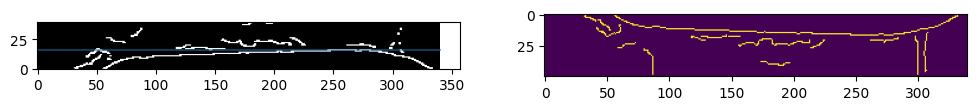

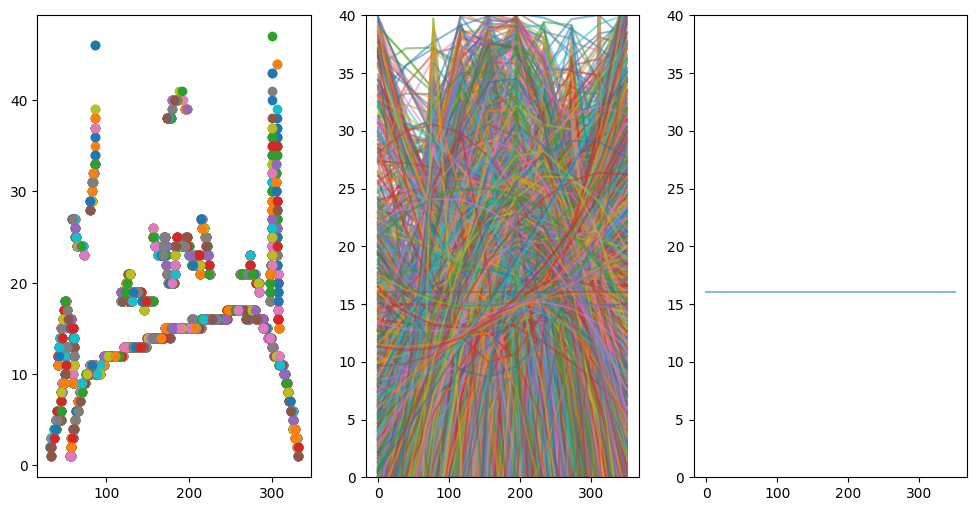

In [13]:
img_top_early=(crop(get_avg_img(50, 3)))[2]
img_top_late=(crop(get_avg_img(570, 3)))[2]

can_top_early = ski.feature.canny(denoise_tv_chambolle(img_top_early))
can_top_late = ski.feature.canny(denoise_tv_chambolle(img_top_late))

sobel_vert = ski.filters.sobel_h(can_top_early) > 0 

fig, axes = plt.subplots(1, 2, figsize=(12, 12))
axes[0].imshow(sobel_vert, cmap=cm.gray)
axes[1].imshow(can_top_early)

#plt.subplotsfind_polynomial(1, 1, figsize=(12, 12))
#print((find_polynomial(can_top_early)[0]))
plot_polynomial(axes[0], (find_polynomial(can_top_early, degree = 2, it = 200)[0])[::-1], imgsize = can_top_early.shape[1])

#axes[0].imshow(can_top_early)

#fig, axes = plt.subplots(1, 1, figsize=(12, 12))
#plot_polynomial(axes, (find_polynomial(img_top_early)[0]))
#axes.hist(img_top_ear)


[-46.59228674  -9.26264581  10.1800457   16.93310516  16.70204466
  14.49986195  13.44633144  13.5672952   10.59395393  -5.23784205]
[  0.          37.77777778  75.55555556 113.33333333 151.11111111
 188.88888889 226.66666667 264.44444444 302.22222222 340.        ]


/tmp/ipykernel_157679/491873341.py:9: RankWarning: Polyfit may be poorly conditioned
  coe = np.polyfit(x, y, 5)


True

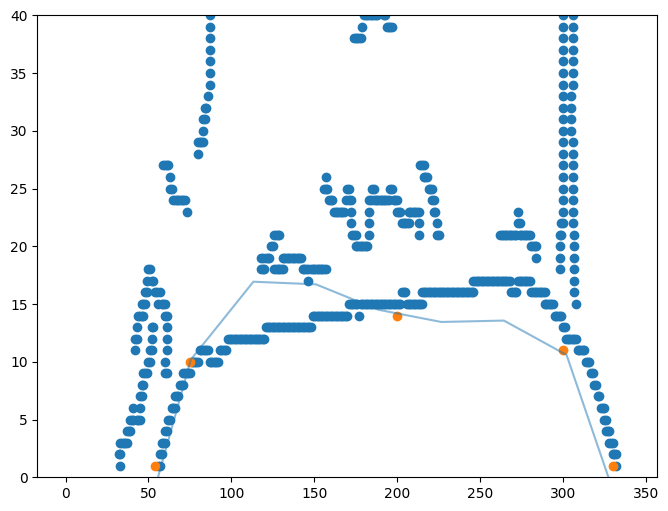

In [14]:
fig, axes = plt.subplots(1, 1, figsize=(8, 6))
points = np.nonzero(can_top_early)
axes.scatter(points[1], points[0])
#plot_polynomial(axes, (find_polynomial(can_top_early)[0]), imgsize = 300)
#handbuilt curve that we want
x = [75, 200, 300, 54, 330]
y = [10, 14, 11, 1, 1]
axes.scatter(x, y)
coe = np.polyfit(x, y, 5)
plot_polynomial(axes, coe[::-1], imgsize = can_top_early.shape[1])

x = np.linspace(0, can_top_early.shape[1], 10)
print(PolyCoefficients(x, coe[::-1]))
print(x)

is_sane = generate_sanity(can_top_early.shape[1])
is_sane(coe[::-1])

In [15]:
print(can_top_early.shape[1])


340
